In [19]:
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.getOrCreate()

In [20]:
from datetime import datetime, date
import pandas as pd
from pyspark.sql import Row

df = spark.createDataFrame([
    Row(a=1, b=2., c='string1', d=date(2000, 1, 1), e=datetime(2000, 1, 1, 12, 0)),
    Row(a=2, b=3., c='string2', d=date(2000, 2, 1), e=datetime(2000, 1, 2, 12, 0)),
    Row(a=4, b=5., c='string3', d=date(2000, 3, 1), e=datetime(2000, 1, 3, 12, 0))
])
df.show()

+---+---+-------+----------+-------------------+
|  a|  b|      c|         d|                  e|
+---+---+-------+----------+-------------------+
|  1|2.0|string1|2000-01-01|2000-01-01 12:00:00|
|  2|3.0|string2|2000-02-01|2000-01-02 12:00:00|
|  4|5.0|string3|2000-03-01|2000-01-03 12:00:00|
+---+---+-------+----------+-------------------+



In [21]:
import os
import dotenv

# Get parquet data from Kaggle
targ_dir = '../data/pyspark_test'
if not (os.path.isdir(targ_dir) and len(os.listdir(targ_dir))==4):
    if 'KAGGLE_API_TOKEN' not in os.environ:
        dotenv.load_dotenv()
    import kaggle
    kaggle.api.dataset_download_files('robikscube/foursquare-location-matching-parquet', 
                                      targ_dir, 
                                      force=True, 
                                      unzip=True)

train = spark.read.parquet(os.path.join(targ_dir, 'train.parquet'))
print(train.count())
train.printSchema()

1138812
root
 |-- id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- address: string (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- zip: string (nullable = true)
 |-- country: string (nullable = true)
 |-- url: string (nullable = true)
 |-- phone: string (nullable = true)
 |-- categories: string (nullable = true)
 |-- point_of_interest: string (nullable = true)



In [24]:
train.limit(5).toPandas()

,id,name,latitude,longitude,address,city,state,zip,country,url,phone,categories,point_of_interest
0,E_000001272c6c5d,Café Stad Oudenaarde,50.859975,3.634196,Abdijstraat,Nederename,Oost-Vlaanderen,9700,BE,None,None,Bars,P_677e840bb6fc7e
1,E_000002eae2a589,Carioca Manero,-22.907225,-43.178244,None,None,None,None,BR,None,None,Brazilian Restaurants,P_d82910d8382a83
2,E_000007f24ebc95,ร้านตัดผมการาเกด,13.780813,100.484900,None,None,None,None,TH,None,None,Salons / Barbershops,P_b1066599e78477
3,E_000008a8ba4f48,Turkcell,37.844510,27.844202,Adnan Menderes Bulvarı,None,None,None,TR,None,None,Mobile Phone Shops,P_b2ed86905a4cd3
4,E_00001d92066153,Restaurante Casa Cofiño,43.338196,-4.326821,None,Caviedes,Cantabria,None,ES,None,None,Spanish Restaurants,P_809a884d4407fb


In [18]:
train.count()

1138812

In [40]:
train.filter("state IS NOT NULL")\
      .groupBy('state')\
      .agg(F.count('id').alias('nct'))\
      .orderBy('nct', ascending=False)\
      .limit(10).toPandas()

,state,nct
0,CA,28863
1,NY,21771
2,FL,17204
3,TX,17001
4,東京都,15868
5,Bangkok,11784
6,PA,10501
7,IL,9868
8,MI,8073
9,Selangor,7837


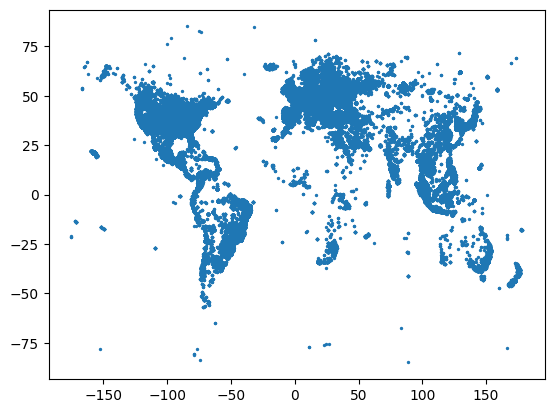

In [ ]:
import matplotlib.pyplot as plt

lat_long = train.select(['latitude', 'longitude']).toPandas()
plt.scatter(lat_long['longitude'], lat_long['latitude'], s=2)
plt.show()

In [ ]:
# Next up: https://spark.apache.org/docs/latest/api/python/getting_started/index.html